## PHASE 1: Machine Learning Classification Model ====>> BITCOIN PRICE PREDICTION

## Project Overview:
The Prediction Model is to predict  the price(categories) of bitcoin, Future prediction or Seasonal prediction.

Datasets Overviews:
The data consist of the daily price prediction in USD from 2010 to 2026. It includes OpenPrice,HighPrice, LowPrice, ClosePrice, Daily trading Volume and PriceCategoies.

**Key Features**
1. Daily Price(2010 - 2026)
2. USD Prices(Open, High, Low, and Close)
3. Daily Volume Trading
4. Price Categories Low/ Medium/ High

Using a machine learning classification models to predict the categories for bitcoin price

1. Logistic Regression
2. DecisionTreeClassifier
3. RandomForest Classifier
4. XgboostClassifier

## Importing all the neccessary libraries

In [1]:
import os
import re
import io
import joblib
import sys
import subprocess

# installing all the packages on the local directories
Packages = [
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "xgboost",
    "imbalanced-learn"
]

for package in Packages:
    subprocess.check_call([sys.executable, "-m", "pip", "install", package, "--quiet"])

print("All libaries installed successfully")

# Import all Machine Learning model from the sckitlearn libraries
# Data Handling
import pandas as pd
import numpy as np

# Data Visulization 
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit learn libraries Models

from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder,LabelBinarizer
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


# Model metrics
from sklearn.metrics import(
    f1_score,
    accuracy_score,
    precision_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    recall_score
)

from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

# Setting all the displays
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10,6)
pd.set_option("display.max_column", None)
pd.set_option("display.max_row",100)
os.makedirs("notebooks/eda_output", exist_ok=True)
%matplotlib inline

print("All libraries imported successfully and Display set successfully")

All libaries installed successfully
All libraries imported successfully and Display set successfully


## LOADING & READING OF DATASET

In [2]:
# Importing and reading dataset

df = pd.read_csv(r"bitcoin.csv")
print("\n DATASET OVERVIEWS")
print("=" * 100)

print(f"The shpe of the loaded dataset: {df.shape}")
print(f"Total length of the Dataset loaded: {len(df)}")
print(f"The shape of the datasets: {df.shape[0]} rows {df.shape[1]} columns")



 DATASET OVERVIEWS
The shpe of the loaded dataset: (5883, 7)
Total length of the Dataset loaded: 5883
The shape of the datasets: 5883 rows 7 columns


In [3]:
df.head(10)

,Date,Open,High,Low,Close,Volume,PriceCategory
0,2010-01-01,0.3,0.303428,0.295510,0.3,715.8,Low
1,2010-01-02,0.3,0.304377,0.299459,0.3,2028.3,Low
2,2010-01-03,0.3,0.303736,0.295858,0.3,273.0,Low
3,2010-01-04,0.3,0.303406,0.298489,0.3,1452.0,Low
4,2010-01-05,0.3,0.302715,0.296330,0.3,1002.6,Low
5,2010-01-06,0.3,0.303982,0.298127,0.3,872.7,Low
6,2010-01-07,0.3,0.302794,0.299572,0.3,421.2,Low
7,2010-01-08,0.3,0.305383,0.295792,0.3,1030.5,Low
8,2010-01-09,0.3,0.305793,0.297143,0.3,2379.9,Low
9,2010-01-10,0.3,0.302486,0.295572,0.3,310.5,Low


## BITCOIN DATASET CLEANING

In [4]:
# Chceking the datatypes of the datasets

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5883 entries, 0 to 5882
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           5883 non-null   str    
 1   Open           5883 non-null   float64
 2   High           5883 non-null   float64
 3   Low            5883 non-null   float64
 4   Close          5883 non-null   float64
 5   Volume         5883 non-null   float64
 6   PriceCategory  5883 non-null   str    
dtypes: float64(5), str(2)
memory usage: 403.7 KB


In [5]:
# Checking the missing_values in the dataset
missing = df.isna().sum()

# Checking the duplicated vaues

duplicates = df.duplicated().sum()


print(f"Missing Values:\n{missing}")
print(f"\nDuplicates Values:{duplicates}")

Missing Values:
Date             0
Open             0
High             0
Low              0
Close            0
Volume           0
PriceCategory    0
dtype: int64

Duplicates Values:0


## EXPLORATORY DATA DATA ANALYSIS

In [6]:
# Data manipulation

# Converting the Date in to DateTime Format

df["Date"] = pd.to_datetime(df["Date"])

df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df.drop(columns="Date",inplace=True)

df.info()

df.head()

<class 'pandas.DataFrame'>
RangeIndex: 5883 entries, 0 to 5882
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Open           5883 non-null   float64
 1   High           5883 non-null   float64
 2   Low            5883 non-null   float64
 3   Close          5883 non-null   float64
 4   Volume         5883 non-null   float64
 5   PriceCategory  5883 non-null   str    
 6   Year           5883 non-null   int32  
 7   Month          5883 non-null   int32  
 8   Day            5883 non-null   int32  
dtypes: float64(5), int32(3), str(1)
memory usage: 369.2 KB


,Open,High,Low,Close,Volume,PriceCategory,Year,Month,Day
0,0.3,0.303428,0.295510,0.3,715.8,Low,2010,1,1
1,0.3,0.304377,0.299459,0.3,2028.3,Low,2010,1,2
2,0.3,0.303736,0.295858,0.3,273.0,Low,2010,1,3
3,0.3,0.303406,0.298489,0.3,1452.0,Low,2010,1,4
4,0.3,0.302715,0.296330,0.3,1002.6,Low,2010,1,5


In [7]:
def Month_name(Month_int:int) -> int:
    """Converting months into Month names"""
    month = int(Month_int)
    if month == 1:
        return "January"
    elif month == 2:
        return "February"
    elif month == 3:
        return "March"
    elif month == 4:
        return "April"
    elif month == 5:
        return "May"
    elif month == 6:
        return "June"
    elif month == 7:
        return "July"
    elif month == 8:
        return "August"
    elif month == 9:
        return "September"
    elif month == 10:
        return "October"
    elif month == 11:
        return "November"
    else:
        return "December"


df["Month_names"] = df["Month"].apply(Month_name)
df.head()

,Open,High,Low,Close,Volume,PriceCategory,Year,Month,Day,Month_names
0,0.3,0.303428,0.295510,0.3,715.8,Low,2010,1,1,January
1,0.3,0.304377,0.299459,0.3,2028.3,Low,2010,1,2,January
2,0.3,0.303736,0.295858,0.3,273.0,Low,2010,1,3,January
3,0.3,0.303406,0.298489,0.3,1452.0,Low,2010,1,4,January
4,0.3,0.302715,0.296330,0.3,1002.6,Low,2010,1,5,January


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5883 entries, 0 to 5882
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Open           5883 non-null   float64
 1   High           5883 non-null   float64
 2   Low            5883 non-null   float64
 3   Close          5883 non-null   float64
 4   Volume         5883 non-null   float64
 5   PriceCategory  5883 non-null   str    
 6   Year           5883 non-null   int32  
 7   Month          5883 non-null   int32  
 8   Day            5883 non-null   int32  
 9   Month_names    5883 non-null   str    
dtypes: float64(5), int32(3), str(2)
memory usage: 450.6 KB


## UNIVARIATE ANALYSIS

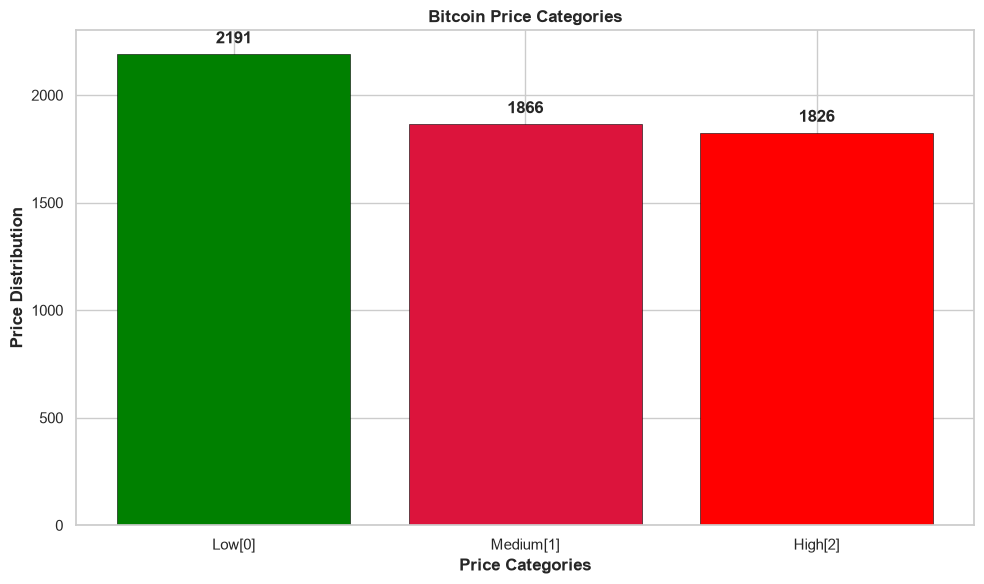

In [9]:
# Price Categories distributions
# Creating a visualizations for Price Categories prediction


Price_Category = df["PriceCategory"].value_counts()

plt.figure(figsize=(10,6))

colors = ["green", "crimson", "red"]

plt.bar(
    ["Low[0]", "Medium[1]", "High[2]"],
    Price_Category,
    color = colors,
    edgecolor="black",
    linewidth=0.4
)


for i, v in enumerate(Price_Category.values):
    plt.text(i, v+50, str(v), ha="center", fontweight="bold")

plt.title("Bitcoin Price Categories",ha="center",fontweight="bold")
plt.xlabel("Price Categories", ha = "center", fontweight= "bold")
plt.ylabel("Price Distribution", ha="center", fontweight="bold")
plt.savefig("notebooks/eda_output/Price_Categories.png")
plt.tight_layout()
plt.show()




## MULTIVARIATE ANALYSIS

In [10]:
# Multivariate analysis on numerical cols
num_cols = df.select_dtypes({"int", "float"}).round(2)

num_cols.head()

# Checking the statistics of the dataaset to check the rate of an outliers

num_cols.describe().round(2).T


,count,mean,std,min,25%,50%,75%,max
Open,5883.0,2.172505e+04,3.011498e+04,0.30,430.57,7193.60,4.226519e+04,9.342920e+04
High,5883.0,2.197372e+04,3.044526e+04,0.30,431.22,7207.98,4.237013e+04,9.528101e+04
Low,5883.0,2.148758e+04,2.979303e+04,0.29,422.14,7057.97,4.148358e+04,9.332645e+04
Close,5883.0,2.173678e+04,3.011995e+04,0.30,430.57,7193.60,4.226519e+04,9.342920e+04
Volume,5883.0,1.087915e+08,1.851098e+08,30.30,1271205.32,17568092.40,1.302297e+08,9.325168e+08
Year,5883.0,2.017560e+03,4.650000e+00,2010.00,2014.00,2018.00,2.022000e+03,2.026000e+03
Month,5883.0,6.490000e+00,3.460000e+00,1.00,3.00,7.00,1.000000e+01,1.200000e+01
Day,5883.0,1.572000e+01,8.810000e+00,1.00,8.00,16.00,2.300000e+01,3.100000e+01


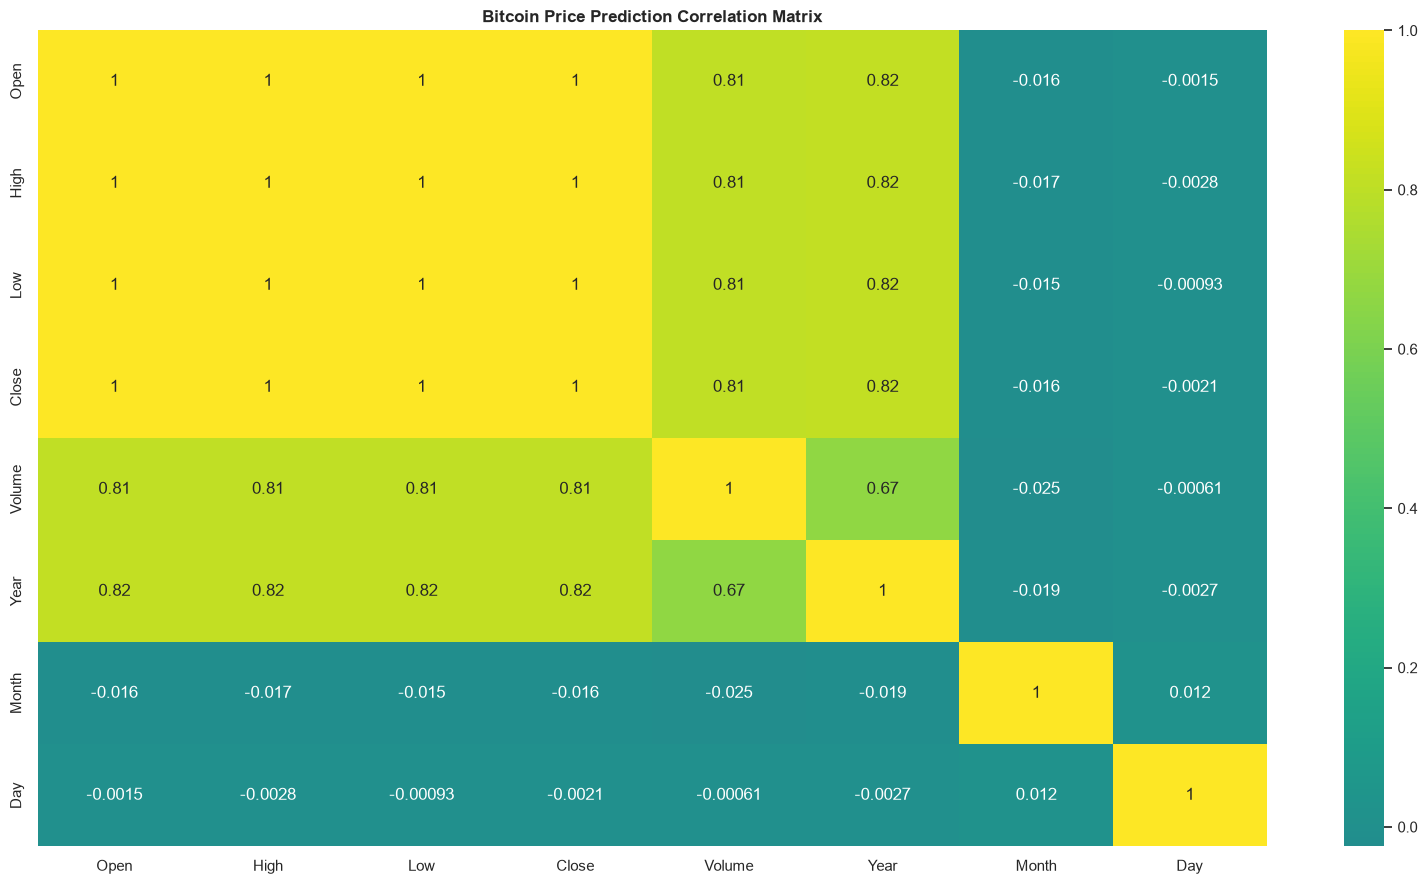

In [11]:
# Getting the correlation coefficient for the numeric columns

corr_matrix = num_cols.corr()

plt.figure(figsize=(16,9))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="viridis",
    center=0
)

plt.title("Bitcoin Price Prediction Correlation Matrix", fontweight="bold")
plt.savefig("notebooks/eda_output/Correlation_matrix02.png", dpi=120)
plt.tight_layout()
plt.show()

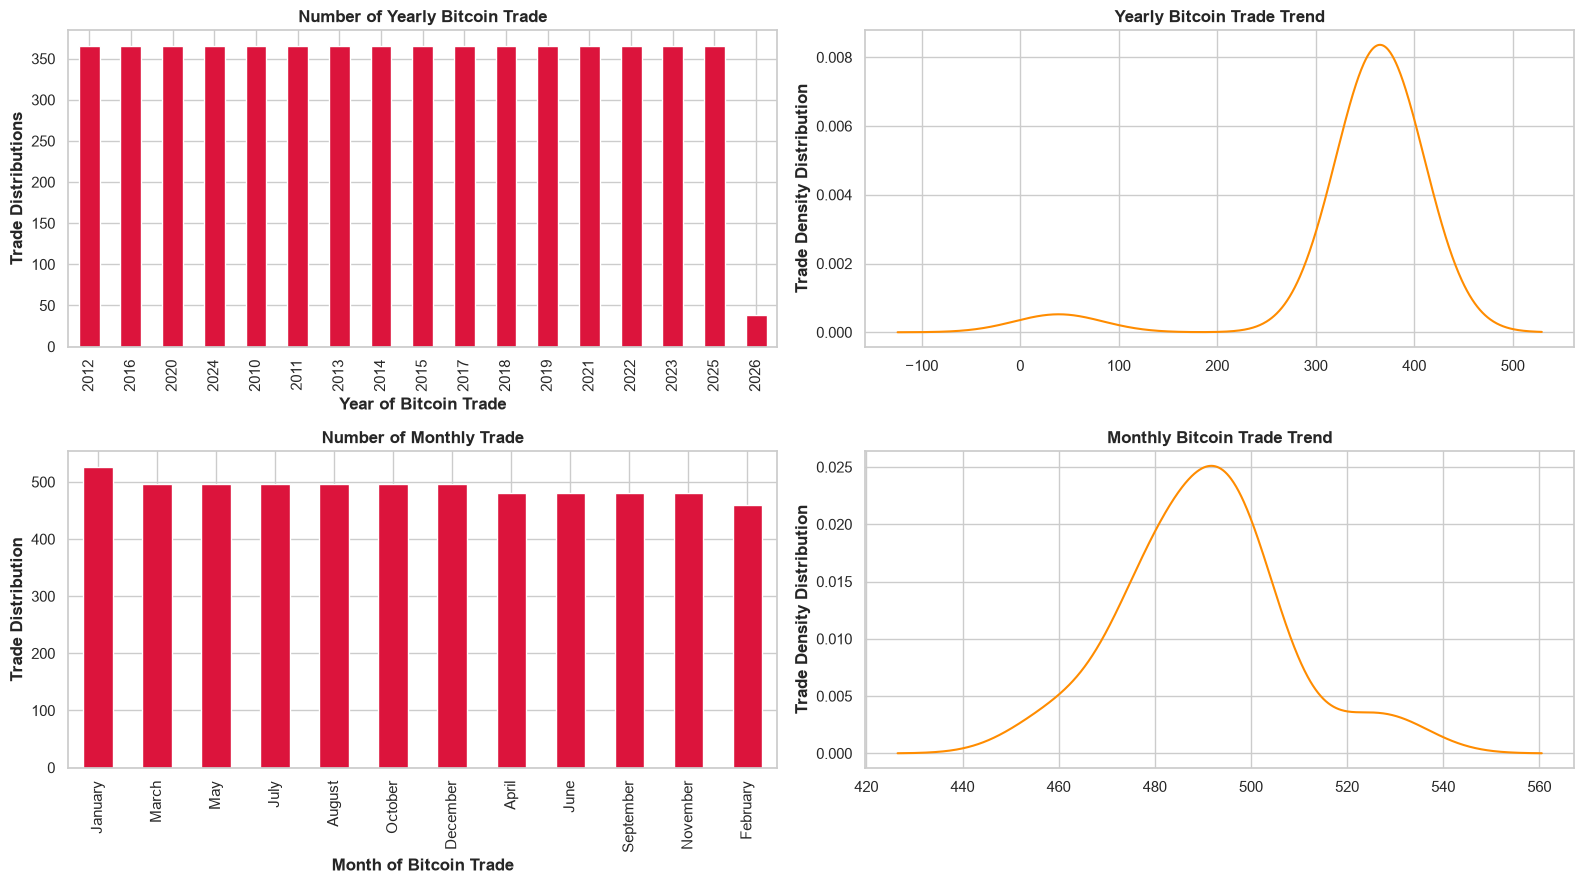

In [12]:
# Checking the level of bitcoin trade based on the years and Monthly trades

fig, ax = plt.subplots(2, 2, figsize=(16,9))
ax=ax.flatten()
# Year analysis

Month_dist = df["Month_names"].value_counts()
Year_dist = df["Year"].value_counts()

Year_dist.plot(
    kind="bar",
    color="crimson",
    ax=ax[0]
)
ax[0].set_title("Number of Yearly Bitcoin Trade", fontweight="bold")
ax[0].set_xlabel("Year of Bitcoin Trade", fontweight="bold")
ax[0].set_ylabel("Trade Distributions", fontweight="bold")

Year_dist.plot(
    kind="kde",
    color="darkorange",
    ax=ax[1]
)
ax[1].set_title("Yearly Bitcoin Trade Trend", fontweight="bold")
ax[1].set_ylabel("Trade Density Distribution", fontweight="bold")

Month_dist.plot(
    kind="bar",
    color="crimson",
    ax=ax[2],
    )
ax[2].set_title("Number of Monthly Trade",fontweight="bold")
ax[2].set_xlabel("Month of Bitcoin Trade", fontweight="bold")
ax[2].set_ylabel("Trade Distribution", fontweight="bold")

Month_dist.plot(
    kind="kde",
    color="darkorange",
    ax=ax[3]
)
ax[3].set_title("Monthly Bitcoin Trade Trend",fontweight="bold")
ax[3].set_ylabel("Trade Density Distribution", fontweight="bold")
plt.savefig("notebooks/eda_output/ Year_MonthTrade_Analysis03.png", dpi=120)
plt.tight_layout()
plt.show()

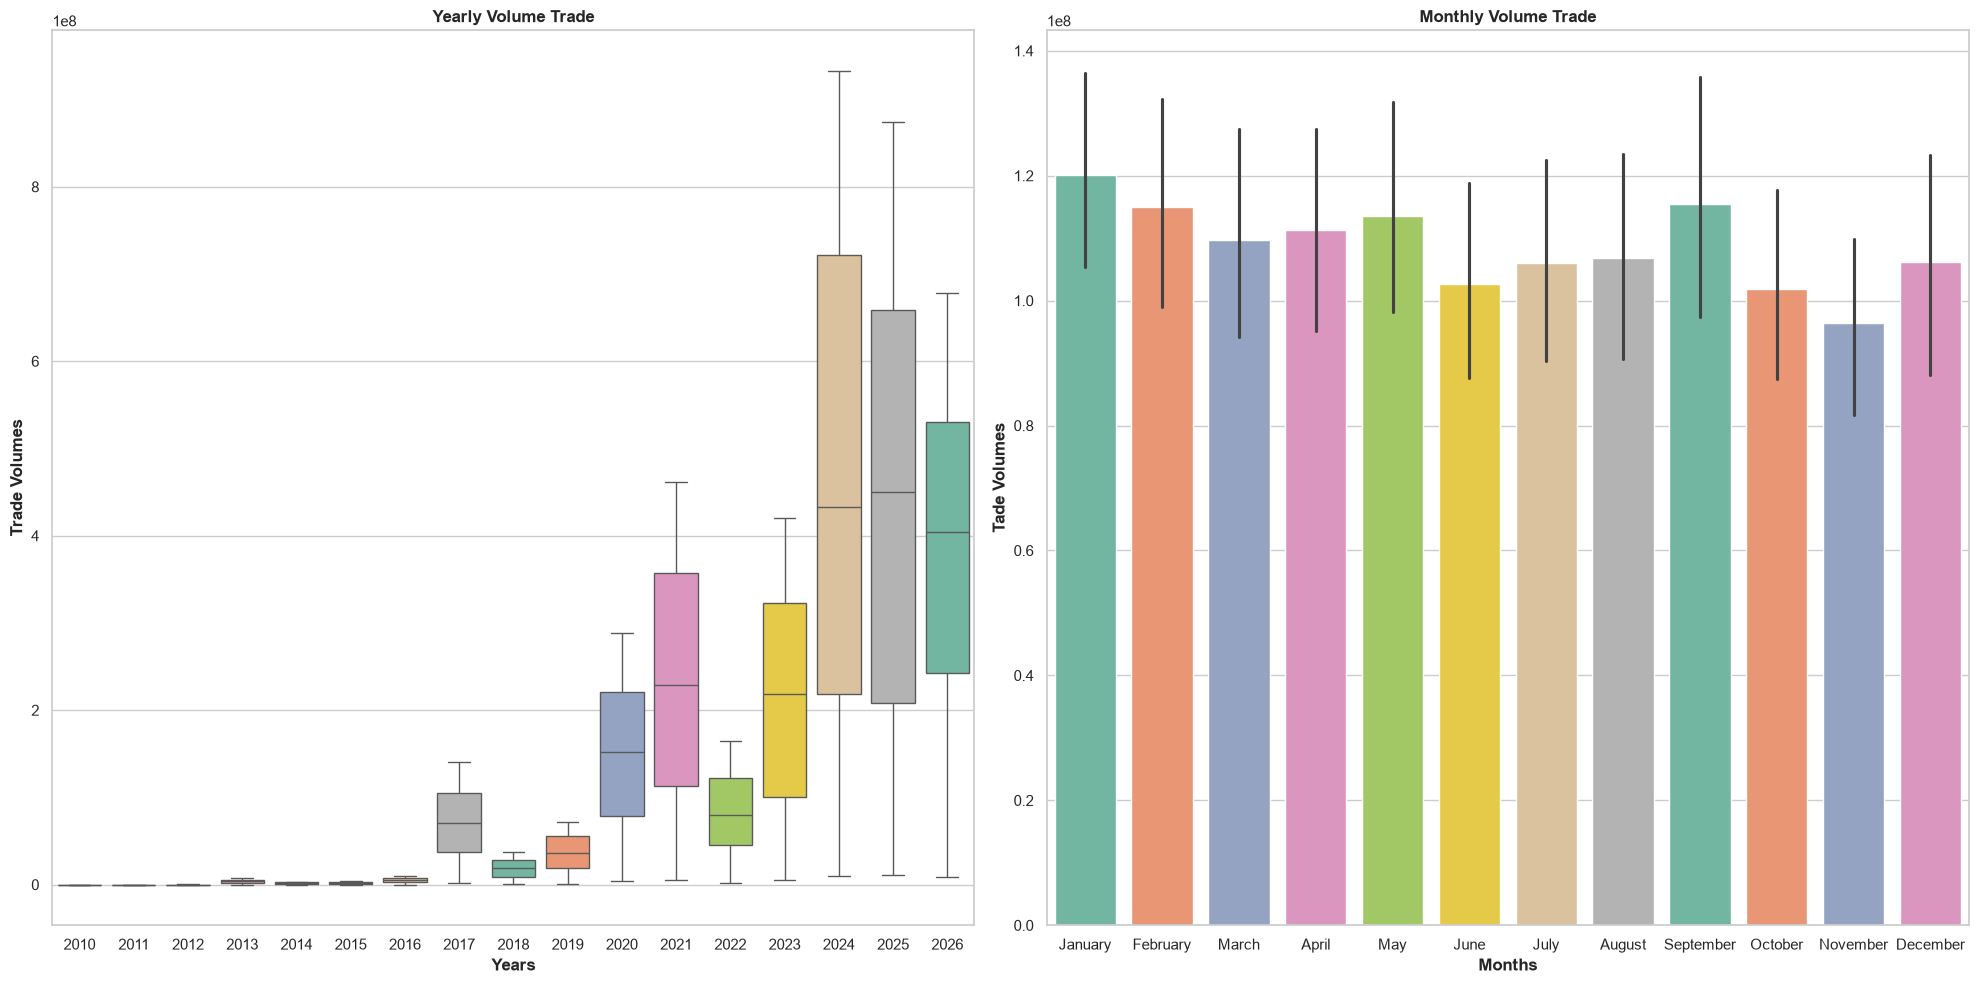

In [13]:
# Checking the the volume Trade Yearly
fig, ax = plt.subplots(1,2, figsize=(20,10))
#ax=ax.flatten()
sns.boxplot(
    data=df,
    x=df["Year"],
    y=df["Volume"],
    hue="Year",
    ax=ax[0],
    palette="Set2",
    legend=False
)
ax[0].set_title("Yearly Volume Trade", fontweight="bold")
ax[0].set_xlabel("Years", fontweight="bold")
ax[0].set_ylabel("Trade Volumes", fontweight="bold")

sns.barplot(
    data=df,
    x=df["Month_names"],
    y=df["Volume"],
    hue="Month_names",
    palette="Set2",
    ax=ax[1],
    legend=False,
)
ax[1].set_title("Monthly Volume Trade",fontweight="bold")
ax[1].set_xlabel("Months",fontweight="bold")
ax[1].set_ylabel("Tade Volumes", fontweight="bold")

plt.savefig("notebooks/eda_output/YearlyTrade_volume",dpi=120)
plt.tight_layout()
plt.show()


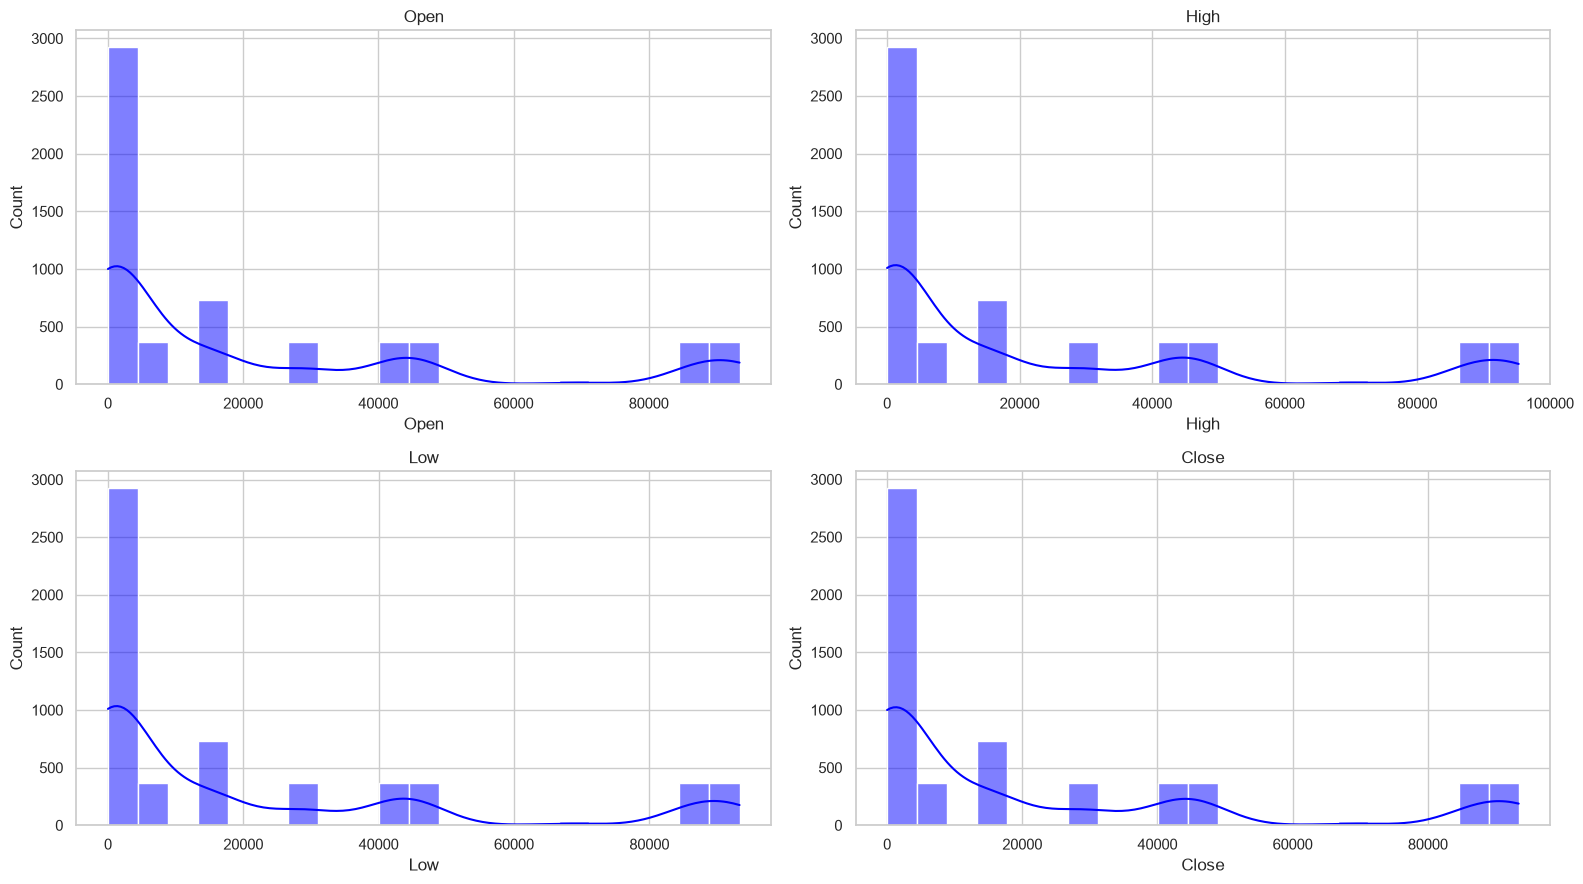

In [14]:
# Comparing all the prices of the bitcoin

Prices = [
    "Open",
    "High",
    "Low",
    "Close",
]

fig, axes = plt.subplots(2,2, figsize=(16,9))

for ax, price in zip(axes.flat, Prices):
    sns.histplot(
        df[price],
        kde=True,
        color="blue", 
        ax=ax
    )
    ax.set_title(price)
plt.tight_layout()
plt.show()

## DATA NORMALIZATION(DATA ENCODING)

In [15]:
# Using oneHotEncoder to transform the Month_names for multiples categories

# Encoding the target
df["PriceCategory"] = df["PriceCategory"].map({"Low":0, "High":1, "Medium":2})

# Encoding the Month_names
df = pd.get_dummies(df, columns=["Month_names"], drop_first=True)


In [16]:
df.head(10)

,Open,High,Low,Close,Volume,PriceCategory,Year,Month,Day,Month_names_August,Month_names_December,Month_names_February,Month_names_January,Month_names_July,Month_names_June,Month_names_March,Month_names_May,Month_names_November,Month_names_October,Month_names_September
0,0.3,0.303428,0.295510,0.3,715.8,0,2010,1,1,False,False,False,True,False,False,False,False,False,False,False
1,0.3,0.304377,0.299459,0.3,2028.3,0,2010,1,2,False,False,False,True,False,False,False,False,False,False,False
2,0.3,0.303736,0.295858,0.3,273.0,0,2010,1,3,False,False,False,True,False,False,False,False,False,False,False
3,0.3,0.303406,0.298489,0.3,1452.0,0,2010,1,4,False,False,False,True,False,False,False,False,False,False,False
4,0.3,0.302715,0.296330,0.3,1002.6,0,2010,1,5,False,False,False,True,False,False,False,False,False,False,False
5,0.3,0.303982,0.298127,0.3,872.7,0,2010,1,6,False,False,False,True,False,False,False,False,False,False,False
6,0.3,0.302794,0.299572,0.3,421.2,0,2010,1,7,False,False,False,True,False,False,False,False,False,False,False
7,0.3,0.305383,0.295792,0.3,1030.5,0,2010,1,8,False,False,False,True,False,False,False,False,False,False,False
8,0.3,0.305793,0.297143,0.3,2379.9,0,2010,1,9,False,False,False,True,False,False,False,False,False,False,False
9,0.3,0.302486,0.295572,0.3,310.5,0,2010,1,10,False,False,False,True,False,False,False,False,False,False,False


## DATA SPLITTING(VERTICAL & HORIZONTAL SPLITTING)

In [17]:
# vertical splitting
# Sperate features from the target variables

X = df.drop(columns=["PriceCategory","Month"])
y = df["PriceCategory"]

print("Features splitted from target variables successfully")

print(f"\nThe Features size after splitting: {X.shape[0]} Bitcoin Price")
print(f"The Target size after splitting: {y.shape[0]} Bitcoin Price")

Features splitted from target variables successfully

The Features size after splitting: 5883 Bitcoin Price
The Target size after splitting: 5883 Bitcoin Price


In [18]:
# Horizontal Splitting 
# Splitting Train variable from Test Variables
# 80% Train & 20% Test

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y)

print("Train variables spliited Test variables splitted successfully")

print(f"\nThe size of Train variable after splitting:{X_train.shape[0]}")
print(f"The size of Test variable after splitting:{X_test.shape[0]}")
print(f"\nThe length of Train variable after splitting:{len(X_train): ,}")
print(f"The length of Test variable after splitting:{len(X_test): ,}")


Train variables spliited Test variables splitted successfully

The size of Train variable after splitting:4706
The size of Test variable after splitting:1177

The length of Train variable after splitting: 4,706
The length of Test variable after splitting: 1,177


In [19]:
num_cols = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "Year",
    "Month",
    "Day"
]


## DATA NORMALIZATION: USING STANDARD SCALER

In [20]:
scaler = StandardScaler()
X_train_scaled= scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [21]:
# Buiding and training of Models

print("Baseline Model =====> LogisticRegression")

lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_train_scaled, y_train)
lr_pred = lr.predict(X_test_scaled)
lr_proba = lr.predict_proba(X_test_scaled)

print(classification_report(y_test, lr_pred,
                            target_names=["Low","Medium","High"]))

print(f"ROC_AUC_SCORE: {roc_auc_score(y_test, lr_proba, multi_class="ovr")}")

Baseline Model =====> LogisticRegression
              precision    recall  f1-score   support

         Low       1.00      1.00      1.00       439
      Medium       1.00      1.00      1.00       373
        High       1.00      1.00      1.00       365

    accuracy                           1.00      1177
   macro avg       1.00      1.00      1.00      1177
weighted avg       1.00      1.00      1.00      1177

ROC_AUC_SCORE: 0.9997846405277389


In [22]:
print("Model ====> DecisionTreeClassifier")

dc = DecisionTreeClassifier(random_state=42, max_depth=100,criterion="entropy")

dc.fit(X_train_scaled, y_train)

dc_pred = dc.predict(X_test_scaled)
dc_proba = dc.predict_proba(X_test_scaled)

print(classification_report(y_test,dc_pred,
                            target_names=["Low","Medium","High"]))

print(f"ROC_AUC_SCORE: {roc_auc_score(y_test,dc_proba, multi_class="ovr")}")

Model ====> DecisionTreeClassifier
              precision    recall  f1-score   support

         Low       1.00      1.00      1.00       439
      Medium       1.00      1.00      1.00       373
        High       1.00      1.00      1.00       365

    accuracy                           1.00      1177
   macro avg       1.00      1.00      1.00      1177
weighted avg       1.00      1.00      1.00      1177

ROC_AUC_SCORE: 1.0


In [23]:
print(f"Model ====> RandomForestClassifier")

rf_model = RandomForestClassifier(random_state=42,
                                  n_estimators=100, n_jobs=9,criterion="entropy" ,max_depth=100)

rf_model.fit(X_train_scaled, y_train)
rf_pred = rf_model.predict(X_test_scaled)
rf_proba = rf_model.predict_proba(X_test_scaled)

print(classification_report(y_test, rf_pred,
                            target_names=["Low","Medium","High"]))

print(f"ROC_AUC_SCORE: {roc_auc_score(y_test,rf_proba, multi_class="ovr")}")


Model ====> RandomForestClassifier
              precision    recall  f1-score   support

         Low       1.00      1.00      1.00       439
      Medium       1.00      1.00      1.00       373
        High       1.00      1.00      1.00       365

    accuracy                           1.00      1177
   macro avg       1.00      1.00      1.00      1177
weighted avg       1.00      1.00      1.00      1177

ROC_AUC_SCORE: 1.0


In [24]:
print("Model ====> XGBClassifier")


xgb_model = XGBClassifier(random_state=42,
                          n_estimators=100,
                          eval_metrics="logloss",
                          verbosity=0,
                          )

xgb_model.fit(X_train_scaled, y_train)

xgb_pred = xgb_model.predict(X_test_scaled)
xgb_proba = xgb_model.predict_proba(X_test_scaled)

print(classification_report(y_test,xgb_pred,
                            target_names=["Low","Medium","High"]))
print(f"ROC_AUC_SCORE: {roc_auc_score(y_test, xgb_proba, multi_class="ovr")}")

Model ====> XGBClassifier
              precision    recall  f1-score   support

         Low       1.00      1.00      1.00       439
      Medium       1.00      1.00      1.00       373
        High       1.00      1.00      1.00       365

    accuracy                           1.00      1177
   macro avg       1.00      1.00      1.00      1177
weighted avg       1.00      1.00      1.00      1177

ROC_AUC_SCORE: 1.0


## PLOTTING THE CONFUSION MATRIX(VISUALIZATION)

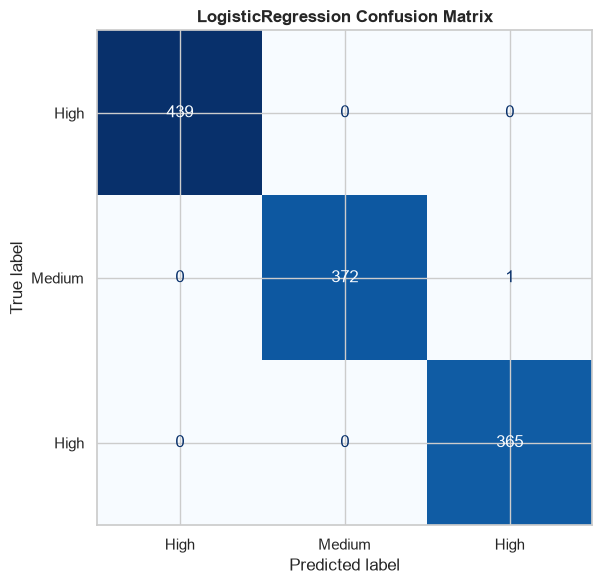

The shape of the Confusion Matrix: (3, 3)

Confusion Matrix:


array([[439,   0,   0],
       [  0, 372,   1],
       [  0,   0, 365]])

In [25]:
# plotting the confuison matrix for each of the models

cm=confusion_matrix(y_test, lr_pred)

fig, ax = plt.subplots(figsize=(10,6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=["High","Medium","High"])

disp.plot(ax=ax, cmap="Blues", colorbar=False)

ax.set_title("LogisticRegression Confusion Matrix", fontweight="bold")
plt.savefig("notebooks/eda_output/CM_LR01",dpi=120)
plt.tight_layout()
plt.show()


print(f"The shape of the Confusion Matrix: {cm.shape}")
print(f"\nConfusion Matrix:")
cm


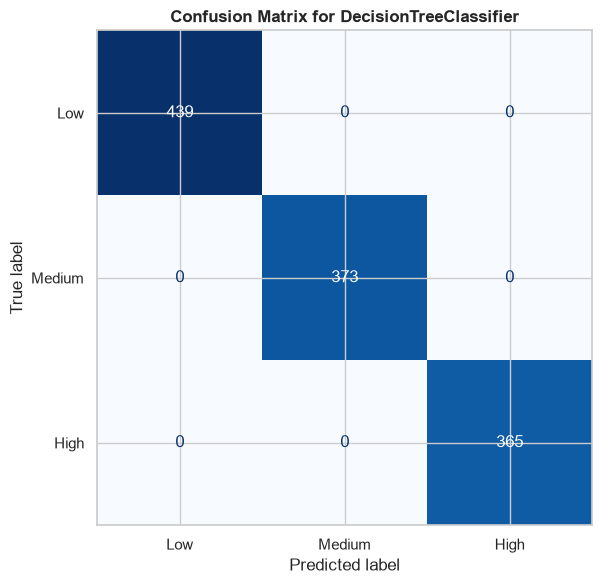

The size of the confusion matrix: (3, 3)


array([[439,   0,   0],
       [  0, 373,   0],
       [  0,   0, 365]])

In [26]:
# Plotting confusion matrix for DecisionTreeClassifier

cm = confusion_matrix(y_test,dc_pred)

fig, ax = plt.subplots(figsize=(10,6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=["Low","Medium","High"])

disp.plot(ax=ax, cmap="Blues", colorbar=False)

ax.set_title("Confusion Matrix for DecisionTreeClassifier",fontweight="bold")
plt.savefig("notebooks/eda_output/CM_DCt02",dpi=120)
plt.tight_layout()
plt.show()

print(f"The size of the confusion matrix: {cm.shape}")
cm

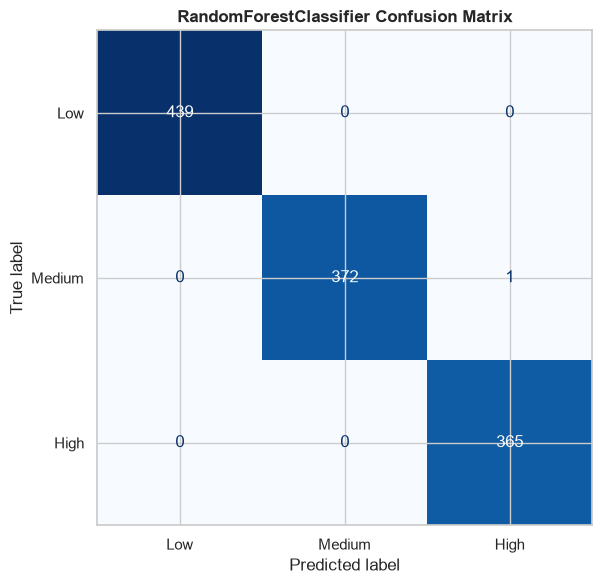

The shape of Randomforestclassifier matrix: (3, 3)


array([[439,   0,   0],
       [  0, 372,   1],
       [  0,   0, 365]])

In [27]:
# Plotting Confusion Matrix for RandomForestClassifier

cm = confusion_matrix(y_test, rf_pred)

fig, ax = plt.subplots(figsize=(10,6))

disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=["Low","Medium","High"])

disp.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("RandomForestClassifier Confusion Matrix", fontweight="bold")
plt.savefig("notebooks/eda_output/RFC03", dpi=120)
plt.tight_layout()
plt.show()

print(f"The shape of Randomforestclassifier matrix: {cm.shape}")
cm

## PLOTTING ROC CURVE FOR ALL THE MODELS

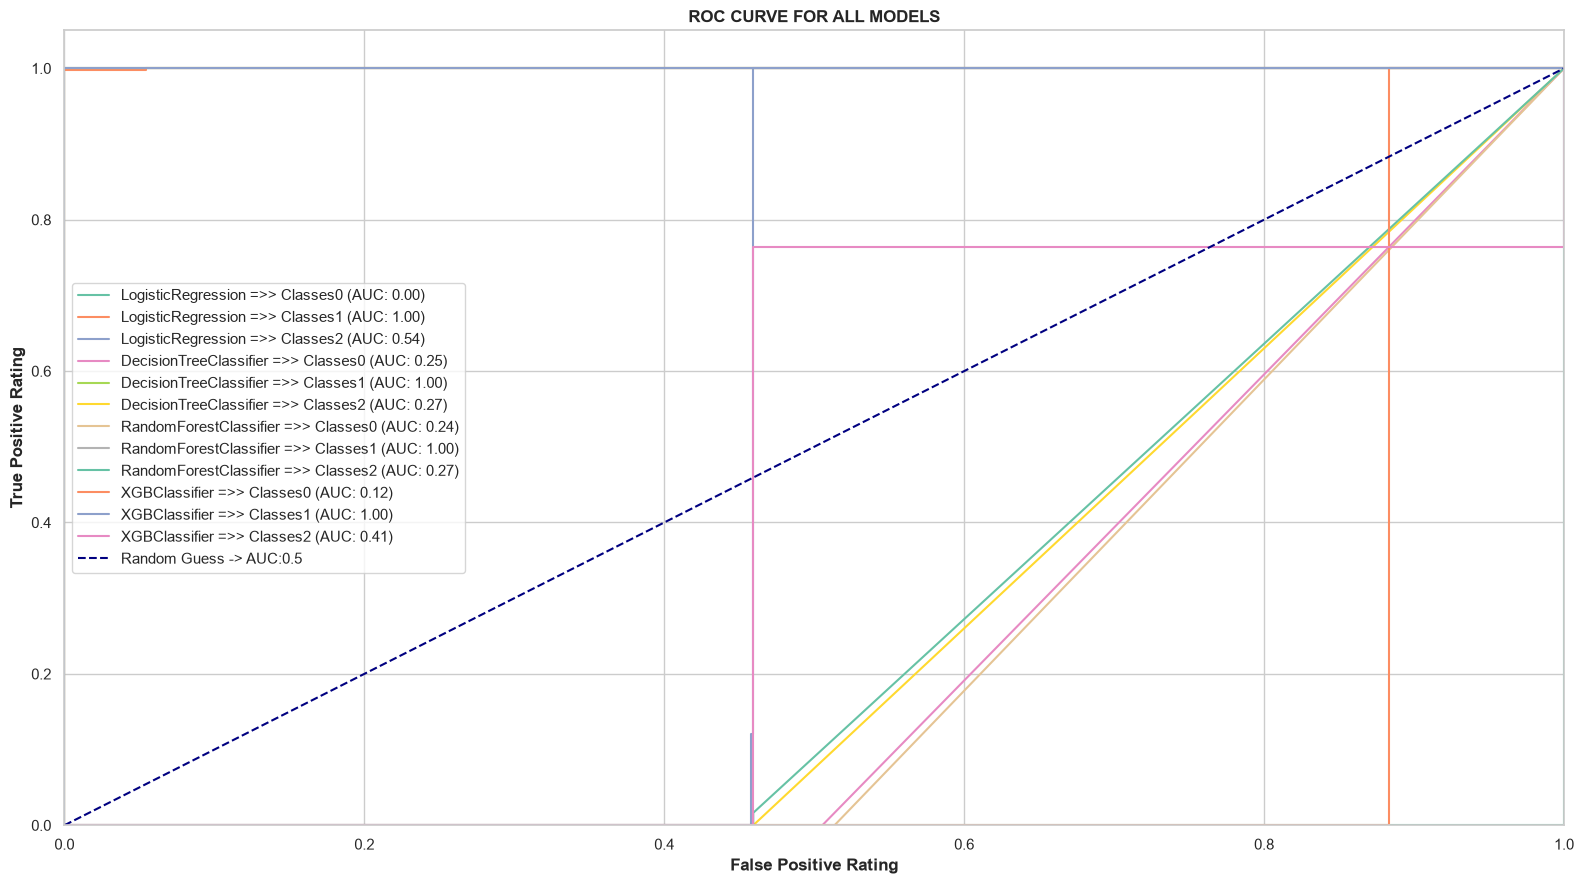

In [28]:
# plotting the roc curve for the models

plt.figure(figsize=(16,9))

Probabilities = [
    ("LogisticRegression", lr_proba),
    ("DecisionTreeClassifier", dc_proba),
    ("RandomForestClassifier", rf_proba),
    ("XGBClassifier", xgb_proba)
]

label_binarizer = LabelBinarizer()
y_test_binarized = label_binarizer.fit_transform(y_test)
classes = label_binarizer.classes_

for name, proba in Probabilities:
    for i, class_label in enumerate(classes):
        y_true_class = y_test_binarized[:, i]
        y_proba_class = proba[:, 1]

        # Calculate roc and auc score
        fpr, tpr, _ = roc_curve(y_true_class, y_proba_class)
        auc = roc_auc_score(y_true_class, y_proba_class)

        # Setting the plotting for tpr, fpr, auc
        plt.plot(fpr, tpr, label=f"{name} =>> Classes{class_label} (AUC:{auc: .2f})")

# PLOTTING A RANDOM GUESS LINE AT 0.5
plt.plot([0,1],[0,1], color="Navy", linestyle="--", label=f"Random Guess -> AUC:0.5")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.title("ROC CURVE FOR ALL MODELS", fontweight="bold")
plt.ylabel("True Positive Rating", fontweight="bold")
plt.xlabel("False Positive Rating", fontweight="bold")
plt.legend()
plt.tight_layout()
plt.show()

## FEATURES IMPORTANCE

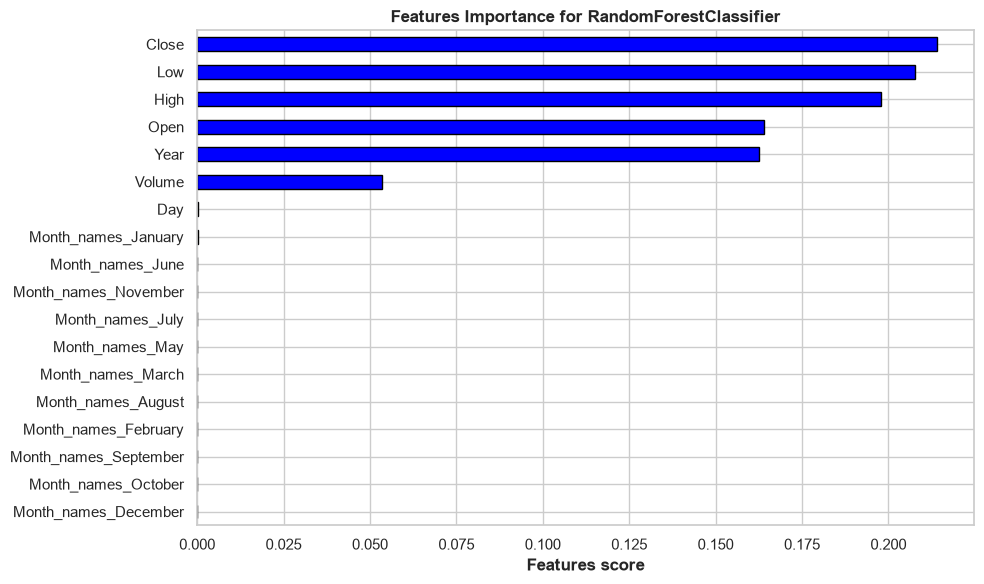

Low       0.21
Close     0.21
High      0.20
Year      0.16
Open      0.16
Volume    0.05
dtype: float64

In [39]:
# Features importance for XGBClassifier ==> Multiclass classification
importances = pd.Series(rf_model.feature_importances_,
index=X.columns)

importances = importances.sort_values(ascending=True)

importances.plot(
    kind="barh",
    color="blue",
    edgecolor="black"
)

plt.title("Features Importance for RandomForestClassifier", fontweight="bold")
plt.xlabel("Features score", fontweight="bold")
plt.savefig("notebooks/eda_output/FEATURES_IMPORTANCE.png", dpi=120)
plt.tight_layout()
plt.show()

importances.tail(6).round(2).sort_values(ascending=False)

## FINAL MODEL COMPARISON

<Figure size 1600x900 with 0 Axes>

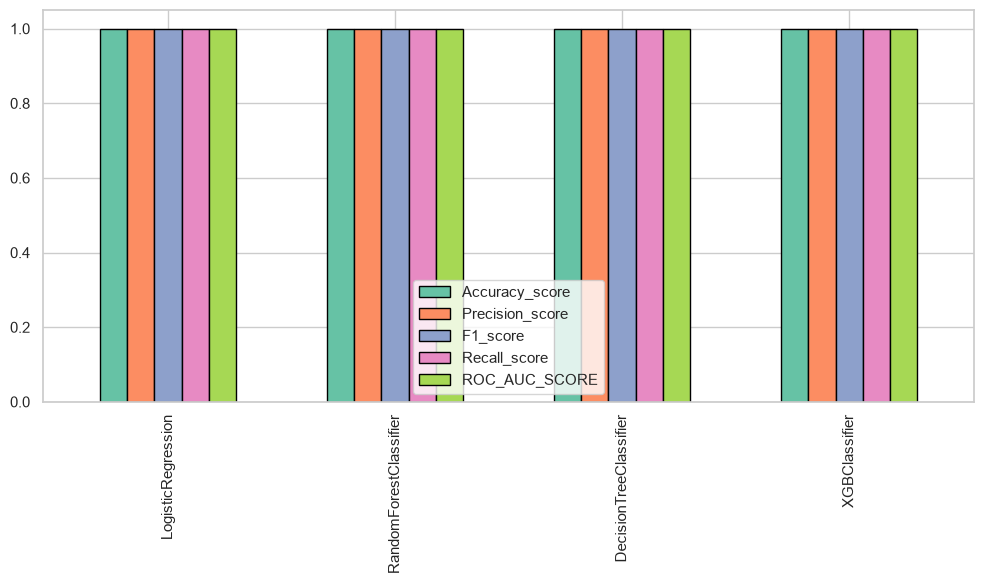

,Accuracy_score,Precision_score,F1_score,Recall_score,ROC_AUC_SCORE
LogisticRegression,1.0,1.0,1.0,1.0,1.0
RandomForestClassifier,1.0,1.0,1.0,1.0,1.0
DecisionTreeClassifier,1.0,1.0,1.0,1.0,1.0
XGBClassifier,1.0,1.0,1.0,1.0,1.0


In [30]:
# Plotting the approprate metric  for each of the models

Models = [
    "LogisticRegression",
    "RandomForestClassifier",
    "DecisionTreeClassifier",
    "XGBClassifier",
]

Metrics = {
    "Accuracy_score":[
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, dc_pred),
        accuracy_score(y_test, xgb_pred)
    ],
    "Precision_score": [
        precision_score(y_test, lr_pred, average="weighted"),
        precision_score(y_test, rf_pred, average="weighted"),
        precision_score(y_test, dc_pred, average="weighted"),
        precision_score(y_test, xgb_pred, average="weighted"),
    ],
    "F1_score":[
        f1_score(y_test, lr_pred, average="weighted"),
        f1_score(y_test, rf_pred, average="weighted"),
        f1_score(y_test, dc_pred, average="weighted"),
        f1_score(y_test, xgb_pred, average="weighted")
    ],
    "Recall_score": [
        recall_score(y_test,lr_pred, average="weighted"),
        recall_score(y_test,rf_pred, average="weighted"),
        recall_score(y_test,dc_pred, average="weighted"),
        recall_score(y_test,xgb_pred, average="weighted")
    ],
    "ROC_AUC_SCORE": [
        roc_auc_score(y_test, lr_proba, multi_class="ovr"),
        roc_auc_score(y_test, rf_proba, multi_class="ovr"),
        roc_auc_score(y_test, dc_proba, multi_class="ovr"),
        roc_auc_score(y_test, xgb_proba, multi_class="ovr")
    ]
}

plt.figure(figsize=(16,9))
results_df = pd.DataFrame(Metrics, index=Models)

results_df.plot(
    kind="bar",
    edgecolor="black",
    width=0.6,
)

plt.tight_layout()
plt.legend()
plt.show()


results_df.round(2)

## EXPORTING THE BITCOIN PRICE PREDICTION MODEL: Using Joblib

In [31]:
import joblib

joblib.dump(scaler, "Bitcoin_scaler.pkl")
joblib.dump(rf_model, "Bitcoin_model.pkl")
joblib.dump(X.columns, "Bitcoin_features.pkl")

print("Bitcoin Price Prediction Model imported successfully")


Bitcoin Price Prediction Model imported successfully
